# Experiment 7: Sentiment Analysis

**Name:** Rudra Gupta  
**SAP ID:** 500120437

**Aim:**
1. Analysis of sentiment and subjectivity.
2. Implement sentiment analysis on the IMDB Movie Reviews dataset.

**Dataset:** [IMDB Dataset of 50K Movie Reviews - Kaggle](https://www.kaggle.com/datasets/lakshmi25npathi/imdb-dataset-of-50k-movie-reviews) (`IMDB Dataset.csv`, kept in this folder).

## Step 1: Install and import the required packages

In [1]:
%pip install textblob scikit-learn pandas matplotlib --quiet

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import re
import pandas as pd
from textblob import TextBlob

### Chart style

In [3]:
import matplotlib.pyplot as plt

SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e8e7e3"
BLUE, BLUE_LIGHT, MUTED = "#2a78d6", "#9ec5f4", "#8a8984"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "font.family": ["Segoe UI", "DejaVu Sans"],
    "font.size": 11, "text.color": INK, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.edgecolor": GRID, "grid.color": GRID, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 15, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 28,
    "figure.dpi": 110,
})


def titles(ax, title, subtitle=None):
    ax.set_title(title, color=INK)
    if subtitle:
        ax.annotate(subtitle, xy=(0, 1), xycoords="axes fraction", xytext=(0, 7),
                    textcoords="offset points", color=INK2, fontsize=10.5, va="bottom")


def hbar(ax, labels, values, color=BLUE, fmt="{:,.0f}", highlight=None, highlight_color=BLUE):
    """Horizontal bars, largest at the top, with the value printed at the end of each bar."""
    labels, values = list(labels)[::-1], list(values)[::-1]
    colors = [highlight_color if l == highlight else color for l in labels]
    bars = ax.barh(labels, values, color=colors, height=0.68, edgecolor=SURFACE, linewidth=2)
    vmax = max(values)
    for b, v in zip(bars, values):
        ax.text(b.get_width() + vmax * 0.012, b.get_y() + b.get_height() / 2, fmt.format(v),
                va="center", fontsize=10, color=INK, zorder=4,
                bbox=dict(facecolor=SURFACE, edgecolor="none", pad=1.5))
    ax.set_xlim(0, vmax * 1.14)
    ax.xaxis.set_visible(False)
    ax.spines[["bottom", "left"]].set_visible(False)
    ax.tick_params(axis="y", length=0, labelsize=10.5, labelcolor=INK)

# Part 1: Analysis of sentiment and subjectivity

**Sentiment analysis** finds the emotional tone of a text. TextBlob uses a lexicon (a dictionary of words with scores) and returns two values:
- **Polarity** from **-1** (very negative) to **+1** (very positive); around 0 is neutral.
- **Subjectivity** from **0** (objective fact) to **1** (personal opinion).

Modifiers are handled too: *very good* scores higher than *good*, and *not good* flips the polarity.

In [4]:
sentences = [
    "This movie was absolutely wonderful and the acting was brilliant!",
    "I really hated the ending, it was boring and predictable.",
    "The film was released in 2019 and runs for 142 minutes.",
    "The food was not good at all.",
    "It's an okay phone, nothing special but it works.",
    "The Earth revolves around the Sun.",
    "What a terrible, awful waste of time!",
    "I think the new design looks quite nice.",
]

def label_polarity(p):
    return "Positive" if p > 0.05 else "Negative" if p < -0.05 else "Neutral"

results = pd.DataFrame([{"Sentence": s,
                         "Polarity": round(TextBlob(s).sentiment.polarity, 3),
                         "Subjectivity": round(TextBlob(s).sentiment.subjectivity, 3)} for s in sentences])
results["Sentiment"] = results["Polarity"].apply(label_polarity)
results["Type"] = results["Subjectivity"].apply(lambda s: "Subjective (opinion)" if s >= 0.5 else "Objective (fact)")
results.index = range(1, len(results) + 1)
results

,Sentence,Polarity,Subjectivity,Sentiment,Type
1,This movie was absolutely wonderful and the ac...,0.667,0.667,Positive,Subjective (opinion)
2,"I really hated the ending, it was boring and p...",-0.700,0.733,Negative,Subjective (opinion)
3,The film was released in 2019 and runs for 142...,0.000,0.000,Neutral,Objective (fact)
4,The food was not good at all.,-0.350,0.600,Negative,Subjective (opinion)
5,"It's an okay phone, nothing special but it works.",0.429,0.536,Positive,Subjective (opinion)
6,The Earth revolves around the Sun.,0.000,0.000,Neutral,Objective (fact)
7,"What a terrible, awful waste of time!",-0.750,0.667,Negative,Subjective (opinion)
8,I think the new design looks quite nice.,0.368,0.727,Positive,Subjective (opinion)


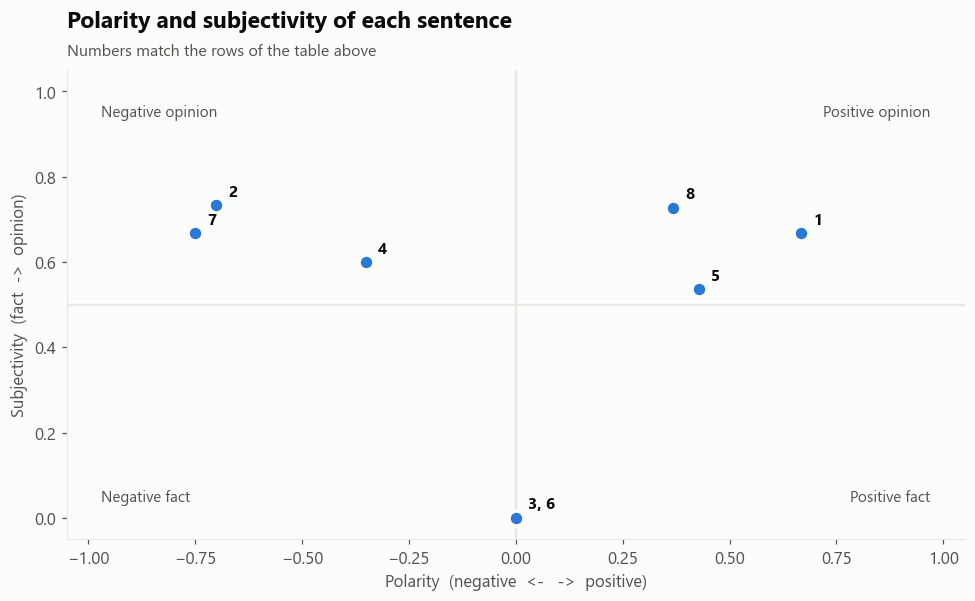

In [5]:
fig, ax = plt.subplots(figsize=(9, 5.6))
ax.axvline(0, color=GRID, linewidth=1.5)
ax.axhline(0.5, color=GRID, linewidth=1.5)
ax.scatter(results["Polarity"], results["Subjectivity"], s=90, color=BLUE, edgecolor=SURFACE, linewidth=2, zorder=3)
# sentences with identical scores share one dot, so label them together (e.g. "3, 6")
for (p, s), grp in results.groupby(["Polarity", "Subjectivity"]):
    ax.annotate(", ".join(map(str, grp.index)), (p, s), xytext=(8, 6), textcoords="offset points",
                fontsize=10.5, fontweight="bold", color=INK, zorder=4)
for x, y, txt in [(-0.97, 0.97, "Negative opinion"), (0.97, 0.97, "Positive opinion"),
                  (-0.97, 0.03, "Negative fact"), (0.97, 0.03, "Positive fact")]:
    ax.text(x, y, txt, ha="left" if x < 0 else "right", va="top" if y > 0.5 else "bottom", color=INK2, fontsize=10)
ax.set_xlim(-1.05, 1.05); ax.set_ylim(-0.05, 1.05)
ax.set_xlabel("Polarity  (negative  <-   ->  positive)")
ax.set_ylabel("Subjectivity  (fact  ->  opinion)")
titles(ax, "Polarity and subjectivity of each sentence", "Numbers match the rows of the table above")
plt.tight_layout()
plt.show()

### How TextBlob scores a sentence
`sentiment_assessments` shows the words (with modifiers) that produced the scores.

In [6]:
for s in [sentences[0], sentences[3]]:
    a = TextBlob(s).sentiment_assessments
    print(s)
    for words, pol, subj, _ in a.assessments:
        print(f"   {' '.join(words):<22} polarity {pol:+.2f}   subjectivity {subj:.2f}")
    print(f"   => overall polarity {a.polarity:+.3f}, subjectivity {a.subjectivity:.3f}")
    print()

This movie was absolutely wonderful and the acting was brilliant!
   absolutely wonderful   polarity +1.00   subjectivity 1.00
   acting                 polarity +0.00   subjectivity 0.00
   brilliant !            polarity +1.00   subjectivity 1.00
   => overall polarity +0.667, subjectivity 0.667

The food was not good at all.
   not good               polarity -0.35   subjectivity 0.60
   => overall polarity -0.350, subjectivity 0.600



**Observations:** opinion sentences (1, 2, 7, 8) have high subjectivity, while facts (3, 6) score 0 subjectivity and neutral polarity. In sentence 4, *not* flips the positive word *good* to a negative score.

# Part 2: Sentiment analysis on IMDB movie reviews

We train a machine-learning classifier that reads a review and predicts whether it is **positive** or **negative**:
1. Clean the text.
2. Convert each review to numbers with **TF-IDF**, which weights words that are frequent in a review but rare across all reviews.
3. Train a **Logistic Regression** classifier on 80% of the reviews and test it on the other 20%.

## 2.1 Load the dataset

In [7]:
df = pd.read_csv("IMDB Dataset.csv")
print("Shape:", df.shape)
print(df["sentiment"].value_counts())
df.head()

Shape: (50000, 2)
sentiment
positive    25000
negative    25000
Name: count, dtype: int64


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


## 2.2 Clean the reviews
Remove HTML line breaks (`<br />`) and other tags, keep only letters, and lowercase.

In [8]:
def clean(text):
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"[^a-zA-Z']", " ", text).lower()
    return re.sub(r"\s+", " ", text).strip()

df["clean"] = df["review"].apply(clean)
print("Before:", df["review"][1][:200])
print("After :", df["clean"][1][:200])

Before: A wonderful little production. <br /><br />The filming technique is very unassuming- very old-time-BBC fashion and gives a comforting, and sometimes discomforting, sense of realism to the entire piece
After : a wonderful little production the filming technique is very unassuming very old time bbc fashion and gives a comforting and sometimes discomforting sense of realism to the entire piece the actors are 


## 2.3 Train-test split and TF-IDF features

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

X_train, X_test, y_train, y_test = train_test_split(
    df["clean"], df["sentiment"], test_size=0.2, random_state=42, stratify=df["sentiment"])

tfidf = TfidfVectorizer(stop_words="english", ngram_range=(1, 2), min_df=2, max_features=50000)
X_train_vec = tfidf.fit_transform(X_train)
X_test_vec = tfidf.transform(X_test)
print(f"Training reviews: {X_train_vec.shape[0]:,}   Test reviews: {X_test_vec.shape[0]:,}   Features: {X_train_vec.shape[1]:,}")

Training reviews: 40,000   Test reviews: 10,000   Features: 50,000


## 2.4 Train the Logistic Regression model

In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

model = LogisticRegression(max_iter=1000)
model.fit(X_train_vec, y_train)
y_pred = model.predict(X_test_vec)

print(f"Test accuracy: {accuracy_score(y_test, y_pred):.2%}")
print()
print(classification_report(y_test, y_pred, digits=3))

Test accuracy: 90.25%

              precision    recall  f1-score   support

    negative      0.911     0.893     0.902      5000
    positive      0.895     0.912     0.903      5000

    accuracy                          0.902     10000
   macro avg      0.903     0.902     0.902     10000
weighted avg      0.903     0.902     0.902     10000



## 2.5 Confusion matrix

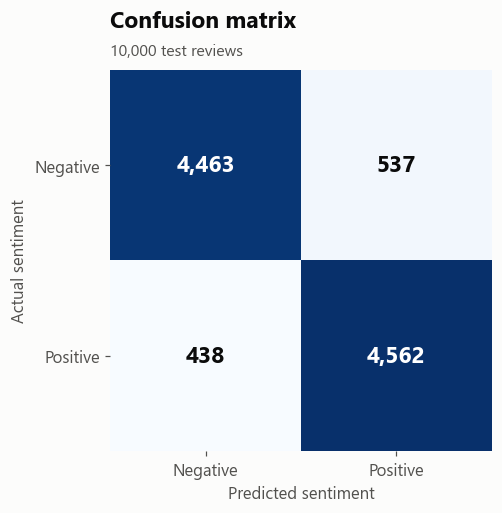

In [11]:
labels = ["negative", "positive"]
cm = confusion_matrix(y_test, y_pred, labels=labels)

fig, ax = plt.subplots(figsize=(5.6, 4.8))
ax.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center", fontsize=15, fontweight="bold",
                color="white" if cm[i, j] > cm.max() / 2 else INK)
ax.set_xticks([0, 1], ["Negative", "Positive"]); ax.set_yticks([0, 1], ["Negative", "Positive"])
ax.set_xlabel("Predicted sentiment"); ax.set_ylabel("Actual sentiment")
ax.spines[:].set_visible(False)
titles(ax, "Confusion matrix", f"{len(y_test):,} test reviews")
plt.tight_layout()
plt.show()

## 2.6 Predicting the sentiment of new reviews

In [12]:
new_reviews = [
    "An absolute masterpiece. The story, the music and the performances were outstanding.",
    "Two hours of my life I will never get back. Dull plot and terrible acting.",
    "Not as good as the first film, but still worth watching for the visuals.",
    "I expected a lot more. The trailer was better than the movie.",
]
probs = model.predict_proba(tfidf.transform([clean(r) for r in new_reviews]))
pd.DataFrame({"Review": new_reviews,
              "Predicted": model.classes_[probs.argmax(axis=1)],
              "Confidence": [f"{p.max():.1%}" for p in probs]})

,Review,Predicted,Confidence
0,"An absolute masterpiece. The story, the music ...",positive,91.6%
1,Two hours of my life I will never get back. Du...,negative,98.6%
2,"Not as good as the first film, but still worth...",positive,88.5%
3,I expected a lot more. The trailer was better ...,negative,51.3%


## Conclusion
**Part 1:** Using TextBlob, we measured the polarity (negative to positive) and subjectivity (fact to opinion) of different sentences. Opinions scored high on subjectivity, facts scored 0, and negation (*not good*) reversed the polarity.

**Part 2:** On the IMDB dataset of 50,000 reviews, we cleaned the text, represented each review with TF-IDF features (single words and word pairs) and trained a Logistic Regression classifier, which reached about 90% accuracy on 10,000 unseen test reviews and correctly classified new reviews.